# 03 · Positional encoding – cho mô hình biết thứ tự

**Vị trí trong luồng dữ liệu:** văn bản → token → embedding **(+ vị trí)** → N khối Transformer → logits → token tiếp theo

Embedding cho biết token *là gì*, nhưng chưa cho biết token *đứng ở đâu*. Notebook này cho thấy vì sao thiếu thông
tin vị trí là một vấn đề thật, rồi cài đặt hai lời giải:

1. **Sinusoidal** – công thức sin/cos cố định của bài báo gốc *Attention Is All You Need* (2017).
2. **Learned** – một bảng embedding cho các vị trí, học cùng mô hình (GPT, GPT-2).

⏱ Thời gian chạy: vài giây.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "vietformer").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import torch
from torch import nn

from vietformer import viz
from vietformer.attention import SelfAttentionHead
from vietformer.data import get_tokenizer
from vietformer.embedding import TokenEmbedding
from vietformer.positional import LearnedPositionalEmbedding, SinusoidalPositionalEncoding
from vietformer.utils import set_seed

viz.set_style()
set_seed(0)

## 1. Vì sao cần vị trí? "Chó cắn người" và "Người cắn chó"

Hai câu có **cùng ba từ**, chỉ khác thứ tự, nhưng nghĩa trái ngược. Self-attention (notebook 04) tính đầu ra của mỗi
token như một trung bình có trọng số của *các token khác*; phép tính đó không hề nhìn vào vị trí. Ta kiểm chứng bằng
một bảng embedding và một head attention ngẫu nhiên, **chưa thêm thông tin vị trí** (tạm tắt causal mask để mỗi
token nhìn được cả câu):

In [2]:
vocab = {"chó": 0, "cắn": 1, "người": 2}
sentence_1 = ["chó", "cắn", "người"]
sentence_2 = ["người", "cắn", "chó"]
ids_1 = torch.tensor([[vocab[w] for w in sentence_1]])  # (B=1, T=3)
ids_2 = torch.tensor([[vocab[w] for w in sentence_2]])

d_model = 16
embedding = nn.Embedding(len(vocab), d_model)
head = SelfAttentionHead(d_model, head_dim=d_model, block_size=8, causal=False)

with torch.no_grad():
    out_1 = head(embedding(ids_1))[0]  # (T, d_model): một vector đầu ra cho mỗi từ
    out_2 = head(embedding(ids_2))[0]

for w in vocab:
    same = torch.allclose(out_1[sentence_1.index(w)], out_2[sentence_2.index(w)], atol=1e-6)
    print(f"Đầu ra của '{w}' ở hai câu giống hệt nhau? {same}")

Đầu ra của 'chó' ở hai câu giống hệt nhau? True
Đầu ra của 'cắn' ở hai câu giống hệt nhau? True
Đầu ra của 'người' ở hai câu giống hệt nhau? True


Không có vị trí, mô hình thấy hai câu như **cùng một túi từ**: "chó" trong câu 1 và "chó" trong câu 2 cho ra cùng một
vector, nên không cách nào biết con nào cắn con nào. Giờ cộng thêm vector vị trí vào embedding trước khi đưa vào attention:

In [3]:
pe = SinusoidalPositionalEncoding(block_size=8, d_model=d_model)

with torch.no_grad():
    out_1 = head(embedding(ids_1) + pe(3))[0]  # (1, 3, d) + (3, d): cộng theo vị trí
    out_2 = head(embedding(ids_2) + pe(3))[0]

for w in vocab:
    same = torch.allclose(out_1[sentence_1.index(w)], out_2[sentence_2.index(w)], atol=1e-6)
    print(f"Đầu ra của '{w}' ở hai câu giống hệt nhau? {same}")

Đầu ra của 'chó' ở hai câu giống hệt nhau? False
Đầu ra của 'cắn' ở hai câu giống hệt nhau? False
Đầu ra của 'người' ở hai câu giống hệt nhau? False


Bây giờ "chó" đứng đầu câu và "chó" đứng cuối câu đã có biểu diễn khác nhau.

> **Ghi chú cho người tò mò.** Khi có causal mask (mỗi token chỉ nhìn về trước), thứ tự đã ảnh hưởng tới kết quả: token
> đầu tiên chỉ nhìn được chính nó. Một số nghiên cứu cho thấy mô hình causal có thể tự suy ra phần nào vị trí, nhưng
> cung cấp vị trí tường minh vẫn là cách phổ biến và dễ học nhất.

## 2. Sinusoidal positional encoding

Bài báo gốc dùng công thức cố định, với `pos` là vị trí và `i` là chỉ số cặp chiều:

$$PE_{(pos,\,2i)} = \sin\left(\frac{pos}{10000^{2i/d}}\right) \qquad PE_{(pos,\,2i+1)} = \cos\left(\frac{pos}{10000^{2i/d}}\right)$$

Hãy hình dung một chiếc đồng hồ có `d/2` kim, mỗi cặp chiều (sin, cos) là một kim quay với tốc độ riêng: kim đầu quay
rất nhanh (đổi theo từng vị trí), kim cuối quay rất chậm. Vị trí của tất cả các kim cùng lúc là một "dấu vân tay"
riêng cho mỗi vị trí. Mã nguồn: `SinusoidalPositionalEncoding` trong `src/vietformer/positional.py`.

shape: (64, 128) | số tham số học được: 0


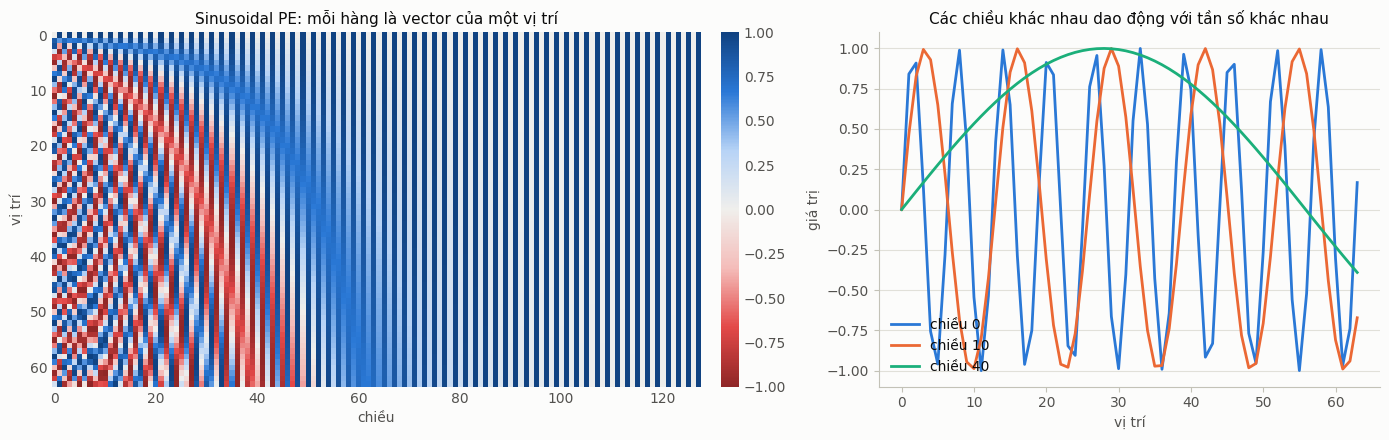

In [4]:
block_size, d_model = 64, 128
sinusoidal = SinusoidalPositionalEncoding(block_size, d_model)
pe = sinusoidal(block_size)  # (64, 128)
print("shape:", tuple(pe.shape), "| số tham số học được:", sum(p.numel() for p in sinusoidal.parameters()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})
viz.plot_matrix(pe, ax=axes[0], cmap=viz.DIVERGING, vmin=-1, vmax=1,
                title="Sinusoidal PE: mỗi hàng là vector của một vị trí", xlabel="chiều", ylabel="vị trí")
for color, dim in zip(viz.COLORS, [0, 10, 40]):
    axes[1].plot(range(block_size), pe[:, dim], color=color, label=f"chiều {dim}")
axes[1].set(xlabel="vị trí", ylabel="giá trị", title="Các chiều khác nhau dao động với tần số khác nhau")
axes[1].legend(loc="lower left")
axes[1].grid(axis="y")
plt.tight_layout()
plt.show()

Bên trái: các chiều đầu (bên trái heatmap) đổi màu liên tục theo vị trí, các chiều sau gần như không đổi. Bên phải:
chiều 0 dao động nhanh, chiều 40 chậm hơn nhiều.

### Vị trí gần nhau thì vector giống nhau

Độ tương đồng cosine giữa vector của hai vị trí chỉ phụ thuộc vào **khoảng cách** giữa chúng, nên heatmap dưới đây
có các đường chéo song song:

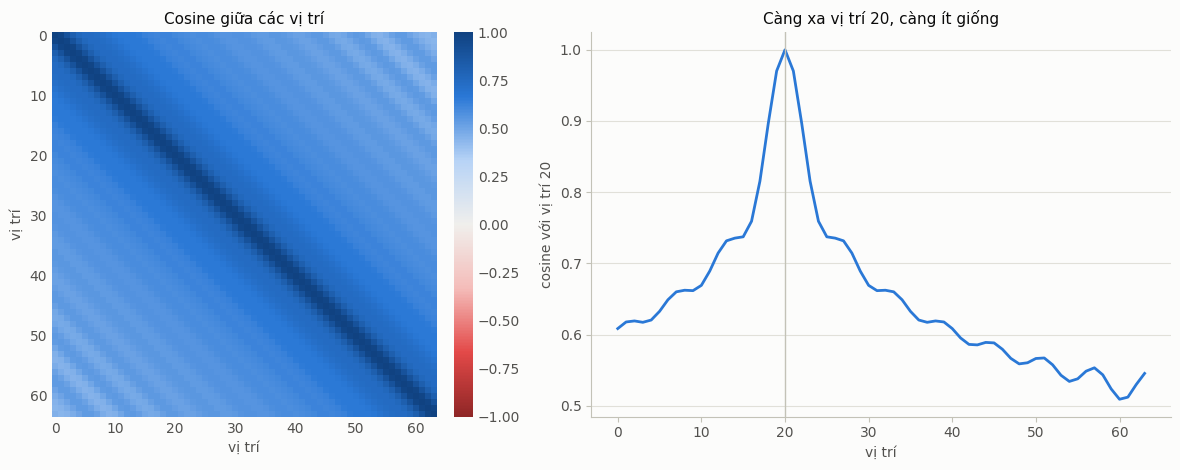

In [5]:
unit = pe / pe.norm(dim=1, keepdim=True)
similarity = unit @ unit.T  # (64, 64): cosine giữa mọi cặp vị trí

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
viz.plot_matrix(similarity, ax=axes[0], cmap=viz.DIVERGING, vmin=-1, vmax=1, aspect="equal",
                title="Cosine giữa các vị trí", xlabel="vị trí", ylabel="vị trí")
axes[1].plot(range(block_size), similarity[20], color=viz.COLORS[0])
axes[1].axvline(20, color=viz.AXIS, linewidth=1)
axes[1].set(xlabel="vị trí", ylabel="cosine với vị trí 20", title="Càng xa vị trí 20, càng ít giống")
axes[1].grid(axis="y")
plt.tight_layout()
plt.show()

Một tính chất đẹp nữa: với mỗi cặp chiều (sin, cos) tần số `ω`, đi thêm `k` vị trí tương đương **xoay** vector
một góc `ω·k`. Phép xoay chỉ phụ thuộc `k`, không phụ thuộc vị trí xuất phát, nên mô hình có thể học được các quy luật
kiểu "nhìn về 3 vị trí trước" bằng một phép biến đổi tuyến tính. Kiểm chứng với cặp chiều đầu tiên:

In [6]:
pos, k = 7, 3
w = 1.0  # tần số của cặp chiều (0, 1) là 1 / 10000^0 = 1
rotation = torch.tensor([[torch.cos(torch.tensor(w * k)), torch.sin(torch.tensor(w * k))],
                         [-torch.sin(torch.tensor(w * k)), torch.cos(torch.tensor(w * k))]])
rotated = rotation @ pe[pos, 0:2]  # xoay vector của vị trí 7 ...
print("Xoay vector vị trí 7 một góc ω·k :", rotated)
print("Vector của vị trí 10 (= 7 + 3)  :", pe[pos + k, 0:2])

Xoay vector vị trí 7 một góc ω·k : tensor([-0.5440, -0.8391])
Vector của vị trí 10 (= 7 + 3)  : tensor([-0.5440, -0.8391])


## 3. Learned positional embedding

Cách của GPT: coi vị trí như một loại "token" và dùng một bảng `nn.Embedding(block_size, d_model)`. Ban đầu bảng là
số ngẫu nhiên; mô hình tự học vector tốt nhất cho từng vị trí trong quá trình huấn luyện.

shape: (64, 128) | số tham số học được: 8192


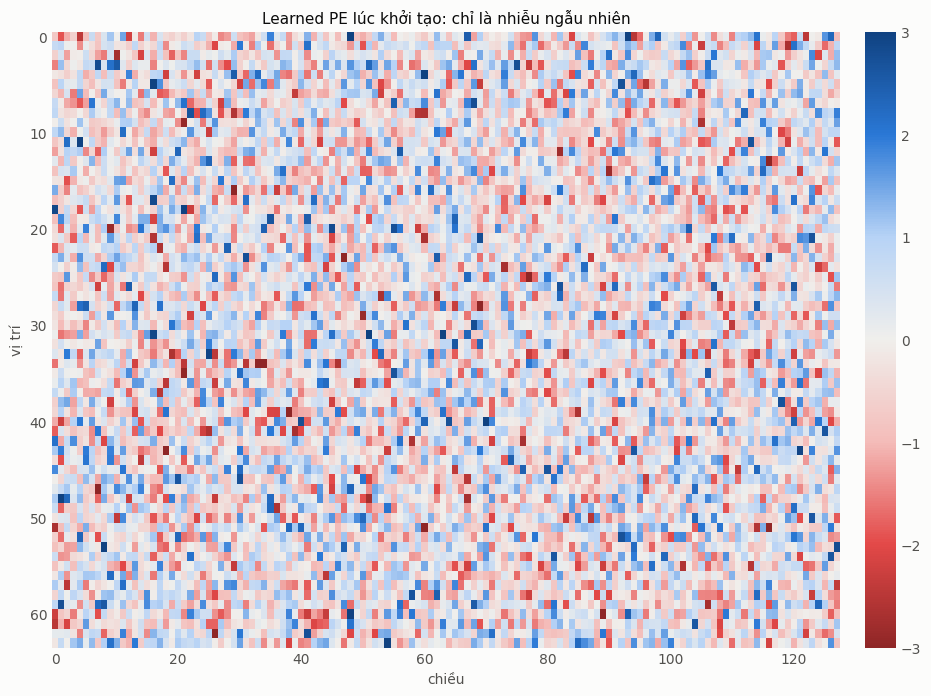

In [7]:
learned = LearnedPositionalEmbedding(block_size, d_model)
print("shape:", tuple(learned(block_size).shape), "| số tham số học được:", sum(p.numel() for p in learned.parameters()))
viz.plot_matrix(learned(block_size).detach(), cmap=viz.DIVERGING, vmin=-3, vmax=3,
                title="Learned PE lúc khởi tạo: chỉ là nhiễu ngẫu nhiên", xlabel="chiều", ylabel="vị trí")
plt.show()

Notebook 08 sẽ vẽ lại bảng này **sau khi huấn luyện** để xem mô hình đã học được gì.

## 4. Ghép vào mô hình: token embedding + positional encoding

Trong `MiniGPT.forward` (`src/vietformer/model.py`) chỉ có đúng một dòng:

```python
x = self.tok_emb(idx) + self.pos_emb(T)   # (B, T, C) + (T, C) -> (B, T, C)
```

Tensor vị trí `(T, C)` được **broadcast** (tự lặp lại) cho cả `B` chuỗi trong batch. Thử với hai câu thơ thật:

In [8]:
tokenizer = get_tokenizer()
lines = ["Trăm năm trong cõi người ta,", "Chữ tài chữ mệnh khéo là ghét"]
idx = torch.tensor([tokenizer.encode(line) for line in lines])  # hai câu cùng có 7 token
B, T = idx.shape

tok_emb = TokenEmbedding(tokenizer.vocab_size, d_model)
x_tok = tok_emb(idx)           # (B, T, C)
x_pos = learned(T)             # (T, C)
x = x_tok + x_pos              # (B, T, C)
print(f"token id {tuple(idx.shape)} → token embedding {tuple(x_tok.shape)} + vị trí {tuple(x_pos.shape)} = {tuple(x.shape)}")

token id (2, 7) → token embedding (2, 7, 128) + vị trí (7, 128) = (2, 7, 128)


## 5. So sánh

| | Sinusoidal | Learned |
|---|---|---|
| Tham số | 0 (công thức cố định) | `block_size × d_model` (ở đây 8.192) |
| Vị trí ≥ `block_size` | tính được (dù mô hình chưa từng thấy) | không có vector → lỗi |
| Dùng trong | Transformer gốc (2017) | GPT, GPT-2, BERT |

Các mô hình hiện đại (LLaMA, Qwen...) thường dùng **RoPE** (rotary positional embedding): thay vì cộng vector vị trí
vào embedding, RoPE *xoay* trực tiếp vector Q và K một góc tỉ lệ với vị trí – chính là tính chất "xoay" ở mục 2.
MiniGPT mặc định dùng learned (`GPTConfig.pos_encoding = "learned"`); bạn có thể đổi sang `"sinusoidal"` để so sánh (bài tập ở notebook 07).

## Tóm tắt

* Attention không phân biệt thứ tự: thiếu vị trí thì "chó cắn người" = "người cắn chó".
* Ta **cộng** một vector vị trí vào embedding của mỗi token.
* Sinusoidal: không tham số, vị trí gần nhau có vector giống nhau, dịch chuyển = phép xoay.
* Learned: một bảng embedding cho vị trí, linh hoạt nhưng giới hạn bởi `block_size`.

**Tiếp theo:** notebook 04 mở hộp đen self-attention, tính tay từng bước.

---

## Bài tập

Đáp án: `solutions/03_positional_encoding.md`

**Bài 1.** Gọi `LearnedPositionalEmbedding(64, 128)(100)` và `SinusoidalPositionalEncoding(64, 128)(100)`. Chuyện gì xảy
ra với mỗi cái? Muốn sinusoidal cho vector ở vị trí 100 thì phải làm gì?

In [9]:
# TODO: thử gọi hai hàm với T = 100 (bọc trong try/except để xem lỗi)

**Bài 2.** Vì sao công thức dùng **cả** sin lẫn cos thay vì chỉ sin? (Gợi ý: nhìn lại phép xoay ở mục 2 – nếu chỉ có
sin, ta có xoay được không?)

**Bài 3.** Kiểm chứng bằng code rằng tích vô hướng `pe[p] · pe[p + k]` chỉ phụ thuộc vào `k`: tính với `k = 5` và
nhiều giá trị `p` khác nhau.

In [10]:
# TODO: với k = 5, in pe[p] @ pe[p + k] cho p = 0, 10, 20, 30